# Questions we can respond to 

| Analyse                               | Question                                                     |
| ------------------------------------- | ------------------------------------------------------------ |
| `popularity` ↔ `vote_average`         | Popularité et qualité perçue sont-elles liées ?              |
| `popularity` ↔ `worldwide_box_office` | Popularité et succès commercial sont-ils liés ?              |
| `vote_count` ↔ `vote_average`         | Le nombre de votes influence-t-il les notes observées ?      |
| `year` ↔ `worldwide_box_office`       | Comment évolue le succès commercial dans le temps ?          |
| `domestic_share`                      | Quelle proportion du box-office vient du marché domestique ? |


In [1]:
import pandas as pd
df = pd.read_csv("../../data/merged/manual_merge/final_merged_manual_numbers_tmdb.csv")

In [2]:
df.head(5)

,tmdb_id,title,original_title,release_date,year,popularity,vote_average,vote_count,adult,rank,domestic_box_office,international_box_office,worldwide_box_office,domestic_share,title_normalized_numbers
0,399579,Alita: Battle Angel,Alita: Battle Angel,2019-01-31,2019,19.5410,7.278,10405,False,20,85838210.0,316061830.0,401900040.0,21.4,alita battle angel
1,530915,1917,1917,2019-12-25,2019,19.0714,7.983,13929,False,22,159227644.0,224482428.0,383710072.0,41.5,NaN
2,757587,1921,1921,2021-07-01,2021,2.2643,5.500,17,False,56,0.0,75017096.0,75017096.0,0.0,NaN
3,1643070,Shelter,Cobijo,2026-03-06,2026,1.8203,6.000,1,False,53,12805541.0,36500000.0,49305541.0,26.0,shelter
4,1767527,Obsession,Одержимость,2026-09-14,2026,1.8521,0.000,0,False,10,263451715.0,253280000.0,516731715.0,51.0,obsession


## Initial description of the dataset

In [3]:
df.shape
df.info()
df.isna().sum()
df.duplicated().sum()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 739 entries, 0 to 738
Data columns (total 15 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   tmdb_id                   739 non-null    int64  
 1   title                     739 non-null    str    
 2   original_title            739 non-null    str    
 3   release_date              739 non-null    str    
 4   year                      739 non-null    int64  
 5   popularity                739 non-null    float64
 6   vote_average              739 non-null    float64
 7   vote_count                739 non-null    int64  
 8   adult                     739 non-null    bool   
 9   rank                      739 non-null    int64  
 10  domestic_box_office       739 non-null    float64
 11  international_box_office  739 non-null    float64
 12  worldwide_box_office      739 non-null    float64
 13  domestic_share            739 non-null    float64
 14  title_normalized_numb

,tmdb_id,year,popularity,vote_average,vote_count,rank,domestic_box_office,international_box_office,worldwide_box_office,domestic_share
count,7.390000e+02,739.000000,739.000000,739.000000,739.000000,739.000000,7.390000e+02,7.390000e+02,7.390000e+02,739.000000
mean,8.785502e+05,2022.566982,19.872647,6.289593,2566.073072,48.350474,7.951879e+07,1.514647e+08,2.309834e+08,35.775643
std,3.719435e+05,2.305124,41.954457,2.105660,3523.313181,28.984161,1.218618e+08,2.189116e+08,3.193858e+08,24.646626
min,3.870000e+04,2019.000000,1.276100,0.000000,0.000000,1.000000,0.000000e+00,0.000000e+00,1.240098e+07,0.000000
25%,5.672685e+05,2021.000000,4.034950,6.300000,82.500000,22.000000,6.553586e+06,3.388350e+07,5.624103e+07,12.000000
50%,8.221820e+05,2023.000000,13.208000,6.900000,1388.000000,48.000000,3.539798e+07,7.501710e+07,1.162039e+08,41.400000
75%,1.173032e+06,2025.000000,21.718000,7.320500,3548.000000,73.000000,9.691754e+07,1.903472e+08,2.707700e+08,52.300000
max,1.769195e+06,2026.000000,633.508500,9.102000,28768.000000,100.000000,9.465821e+08,1.977904e+09,2.721304e+09,100.000000


### distributions

array([[<Axes: title={'center': 'popularity'}>,
        <Axes: title={'center': 'vote_average'}>],
       [<Axes: title={'center': 'vote_count'}>,
        <Axes: title={'center': 'domestic_box_office'}>],
       [<Axes: title={'center': 'international_box_office'}>,
        <Axes: title={'center': 'worldwide_box_office'}>]], dtype=object)

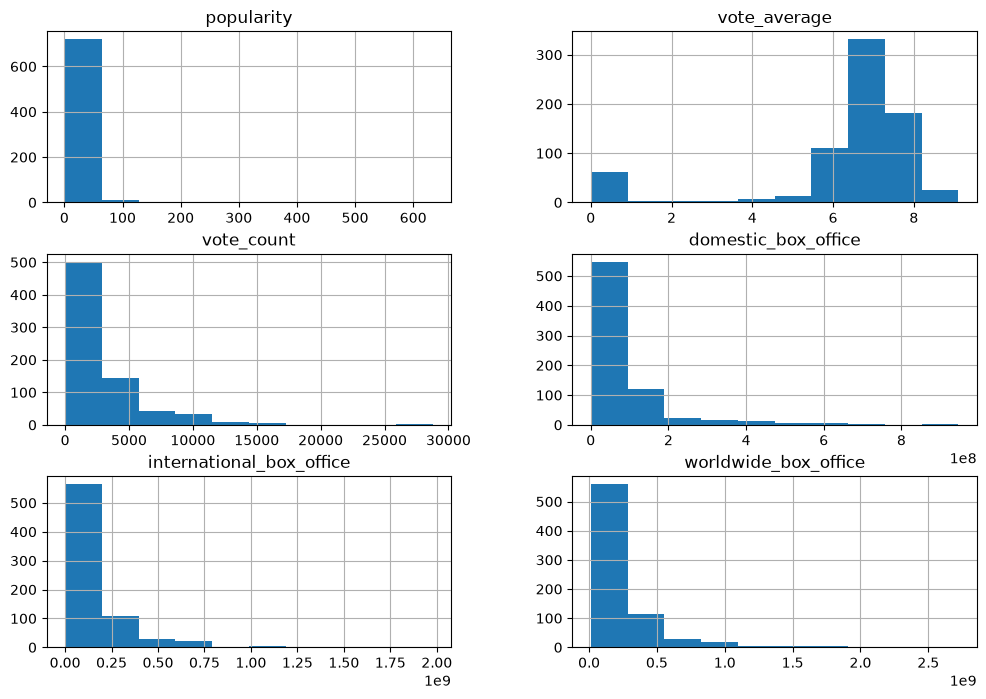

In [4]:
df[['popularity', 'vote_average', 'vote_count',
    'domestic_box_office', 'international_box_office',
    'worldwide_box_office']].hist(figsize=(12,8))

### popularity vs vote_average

<Axes: xlabel='popularity', ylabel='vote_average'>

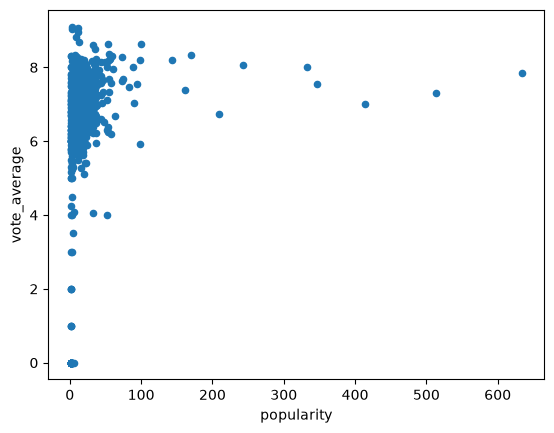

In [6]:
df.plot.scatter(x='popularity', y='vote_average')

### vote_count vs vote_average

<Axes: xlabel='vote_count', ylabel='vote_average'>

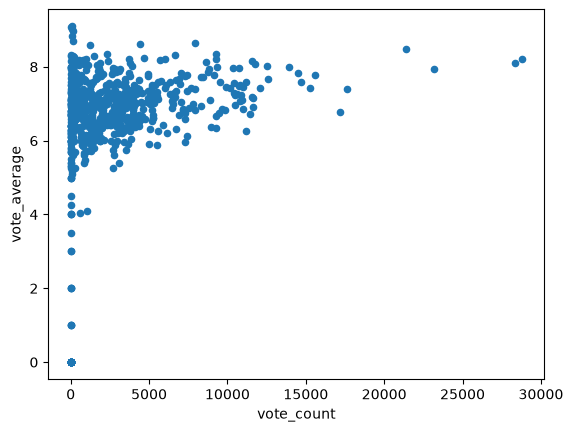

In [7]:
df.plot.scatter(x='vote_count', y='vote_average')

### popularity vs worlwide_box_office

<Axes: xlabel='popularity', ylabel='worldwide_box_office'>

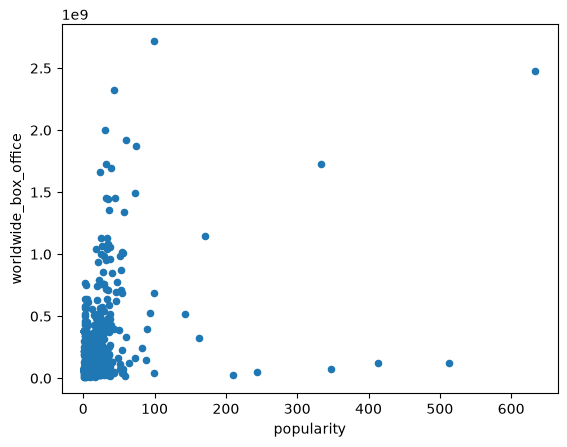

In [31]:
df.plot.scatter(x='popularity', y='worldwide_box_office')

we can't say much because all scatter plots are concentrated, we fill further analsye

### Numeric columns

In [15]:
numeric_cols = [
    'popularity',
    'vote_average',
    'vote_count',
    'rank',
    'domestic_box_office',
    'international_box_office',
    'worldwide_box_office',
    "domestic_share"
]



#### correlation matrix

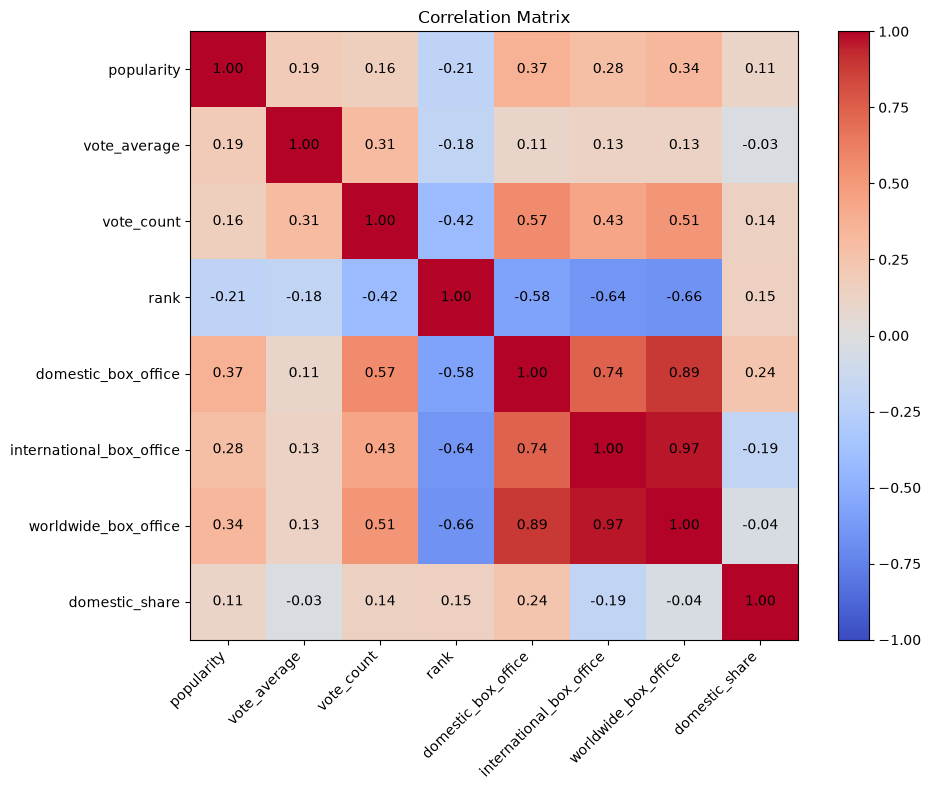

In [16]:
import matplotlib.pyplot as plt
corr = df[numeric_cols].corr()

plt.figure(figsize=(10, 8))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation=45, ha="right")
plt.yticks(range(len(corr.columns)), corr.columns)

for i in range(len(corr)):
    for j in range(len(corr)):
        plt.text(j, i, f"{corr.iloc[i,j]:.2f}",
                 ha="center", va="center")

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

| Variables                                           | Pearson correlation | Interpretation                    |
| --------------------------------------------------- | ------------------: | --------------------------------- |
| `international_box_office` ↔ `worldwide_box_office` |           **0.966** | Very strong positive relationship |
| `domestic_box_office` ↔ `worldwide_box_office`      |           **0.886** | Very strong positive relationship |
| `domestic_box_office` ↔ `international_box_office`  |           **0.735** | Strong positive relationship      |


Les variables liées au box-office présentent de fortes corrélations positives. Le box-office mondial est notamment très fortement corrélé au box-office international (r = 0,966) et au box-office domestique (r = 0,886). Cette relation est cohérente avec la construction du box-office mondial à partir des recettes nationales et internationales

### wordwide vs international box office

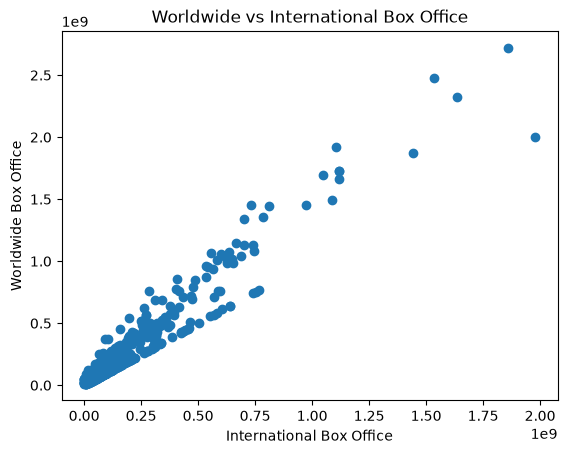

In [17]:
plt.scatter(
    df["international_box_office"],
    df["worldwide_box_office"]
)
plt.xlabel("International Box Office")
plt.ylabel("Worldwide Box Office")
plt.title("Worldwide vs International Box Office")
plt.show()

### rank vs worlwide box office

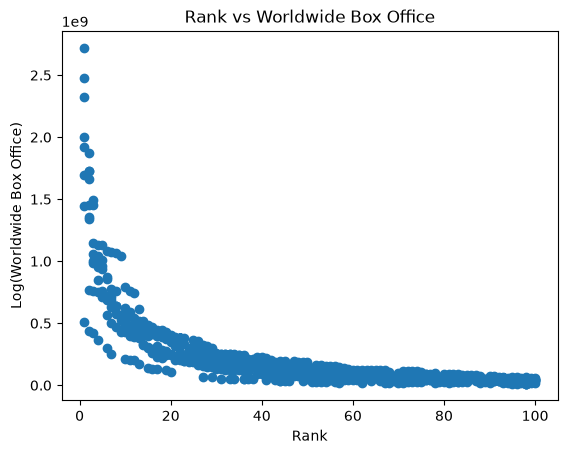

In [26]:
import numpy as np

plt.scatter(df["rank"], df["worldwide_box_office"])
plt.xlabel("Rank")
plt.ylabel("Log(Worldwide Box Office)")
plt.title("Rank vs Worldwide Box Office")
plt.show()

Le rang présente une corrélation négative avec le box-office mondial (r = -0,659). Le nuage de points montre une tendance décroissante : lorsque la valeur numérique du rang augmente, le box-office mondial tend à diminuer.
"We observe a strong association between the Numbers ranking and worldwide box office, which is expected given that the ranking reflects box-office performance."

### worldwide_box_office 

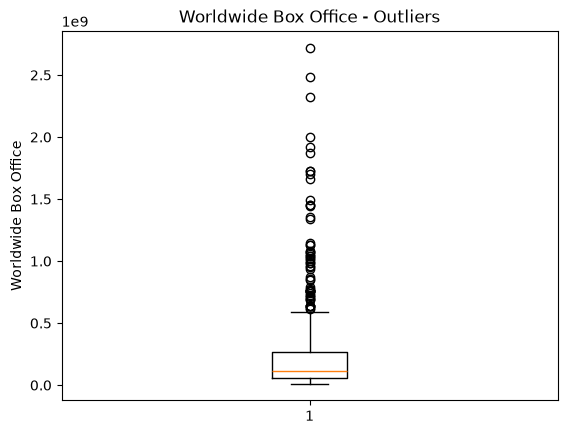

In [21]:
plt.boxplot(df["worldwide_box_office"].dropna())
plt.ylabel("Worldwide Box Office")
plt.title("Worldwide Box Office - Outliers")
plt.show()

from the boxplot we identify outliers

In [ ]:
df.nlargest(10, "worldwide_box_office")[
    ["title", "year", "worldwide_box_office", "popularity", "vote_count"]
]


,title,year,worldwide_box_office,popularity,vote_count
726,Avengers: Endgame,2019,2.721304e+09,98.7212,28768
563,Spider-Man: Brand New Day,2026,2.480707e+09,633.5085,2871
33,Avatar: The Way of Water,2022,2.322902e+09,43.1055,14671
619,Ne Zha 2,2025,2.001155e+09,30.6836,833
435,Spider-Man: No Way Home,2021,1.921207e+09,60.5141,23182
601,Zootopia 2,2025,1.870309e+09,74.1100,3458
296,The Odyssey,2026,1.729811e+09,32.2523,595
567,The Odyssey,2026,1.729811e+09,333.2210,3899
351,Inside Out 2,2024,1.698864e+09,38.8422,7000
705,The Lion King,2019,1.661454e+09,23.3157,10915


as confirmed these movies represent blockbusters

### year analysis

In [33]:
year_analysis = (
    df.groupby("year")
      .agg(
          n_movies=("worldwide_box_office", "count"),
          median_worldwide=("worldwide_box_office", "median"),
          mean_worldwide=("worldwide_box_office", "mean"),
          median_domestic=("domestic_box_office", "median"),
          median_international=("international_box_office", "median"),
          median_domestic_share=("domestic_share", "median")
      )
      .sort_index()
)

year_analysis

,n_movies,median_worldwide,mean_worldwide,median_domestic,median_international,median_domestic_share
year,,,,,,
2019,114,307730211.5,3.582658e+08,109367817.5,199810262.0,41.5
2020,51,40629075.0,9.471512e+07,12611536.0,28501108.0,41.0
2021,95,75017096.0,1.657458e+08,17000612.0,75017096.0,28.6
2022,83,107192068.0,2.340461e+08,39089002.0,60303627.0,44.3
2023,115,117625455.0,2.172285e+08,34553225.0,79965280.0,45.1
2024,95,116392432.0,2.282469e+08,32494740.0,77457281.0,37.5
2025,91,108340555.0,2.413436e+08,37000711.0,70292258.0,39.6
2026,95,77669421.0,2.234243e+08,19971832.0,40585293.0,42.6


by comparing mean and median we can know if during those years there was a blockbuster

### world_wide_boxoffice by year

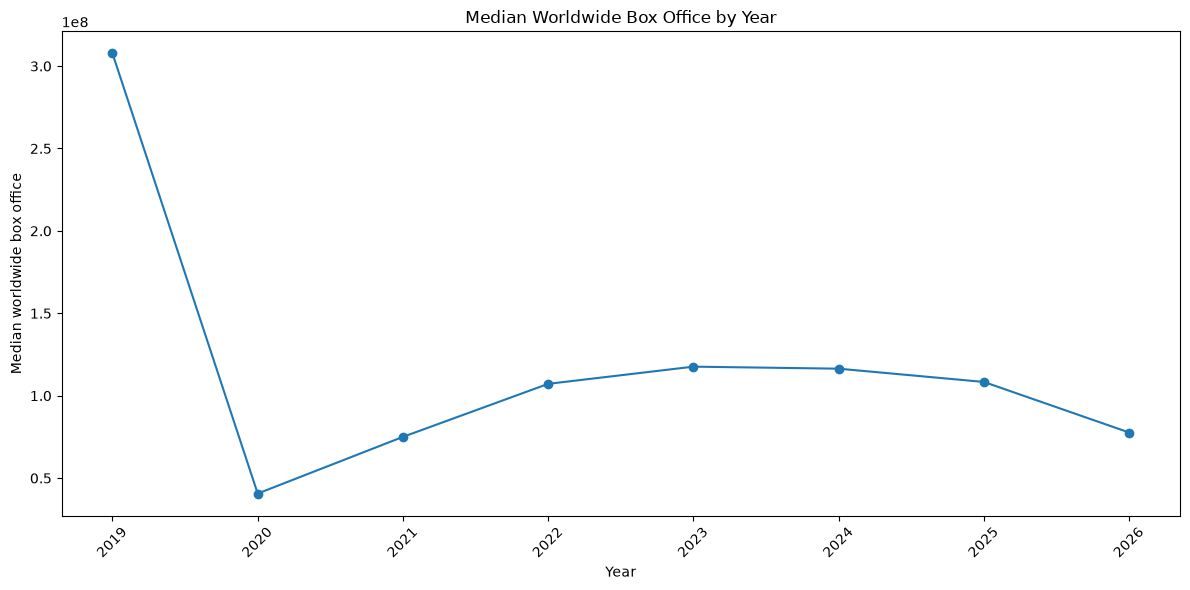

In [35]:
plt.figure(figsize=(12, 6))

plt.plot(
    year_analysis.index,
    year_analysis["median_worldwide"],
    marker="o"
)

plt.xlabel("Year")
plt.ylabel("Median worldwide box office")
plt.title("Median Worldwide Box Office by Year")
plt.xticks(year_analysis.index, rotation=45)
plt.tight_layout()
plt.show()

movies generated more money in 2019 ? --> find another explanation ......

### rank

In [40]:
df['rank']

0      20
1      22
2      56
3      53
4      10
       ..
734    33
735    11
736    59
737    75
738    13
Name: rank, Length: 739, dtype: int64

In [41]:
df["rank"].describe()

count    739.000000
mean      48.350474
std       28.984161
min        1.000000
25%       22.000000
50%       48.000000
75%       73.000000
max      100.000000
Name: rank, dtype: float64

In [42]:
import numpy as np
import pandas as pd

bins = [0, 10, 25, 50, 75, 100]

labels = [
    "1-10",
    "11-25",
    "26-50",
    "51-75",
    "76-100"
]

df["rank_group"] = pd.cut(
    df["rank"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

df[["rank", "rank_group"]].sort_values("rank").head(30)

,rank,rank_group
563,1,1-10
435,1,1-10
619,1,1-10
351,1,1-10
33,1,1-10
726,1,1-10
728,1,1-10
180,1,1-10
296,2,1-10
177,2,1-10


#### rank_groups by box office

In [43]:
rank_analysis = (
    df.groupby("rank_group", observed=True)
      .agg(
          n_movies=("worldwide_box_office", "count"),
          median_worldwide=("worldwide_box_office", "median"),
          mean_worldwide=("worldwide_box_office", "mean"),
          median_domestic=("domestic_box_office", "median"),
          median_international=("international_box_office", "median")
      )
      .reset_index()
)

rank_analysis

,rank_group,n_movies,median_worldwide,mean_worldwide,median_domestic,median_international
0,1-10,77,767409308.0,9.415172e+08,339640400.0,554749272.0
1,11-25,138,383710072.0,3.547914e+08,140063769.0,224482428.0
2,26-50,171,150608996.0,1.557261e+08,57300280.0,88981452.0
3,51-75,186,75017096.0,7.872689e+07,17905715.0,51848534.5
4,76-100,167,49528223.0,4.770277e+07,19802293.0,24178123.0


#### worldwide box office by rank group

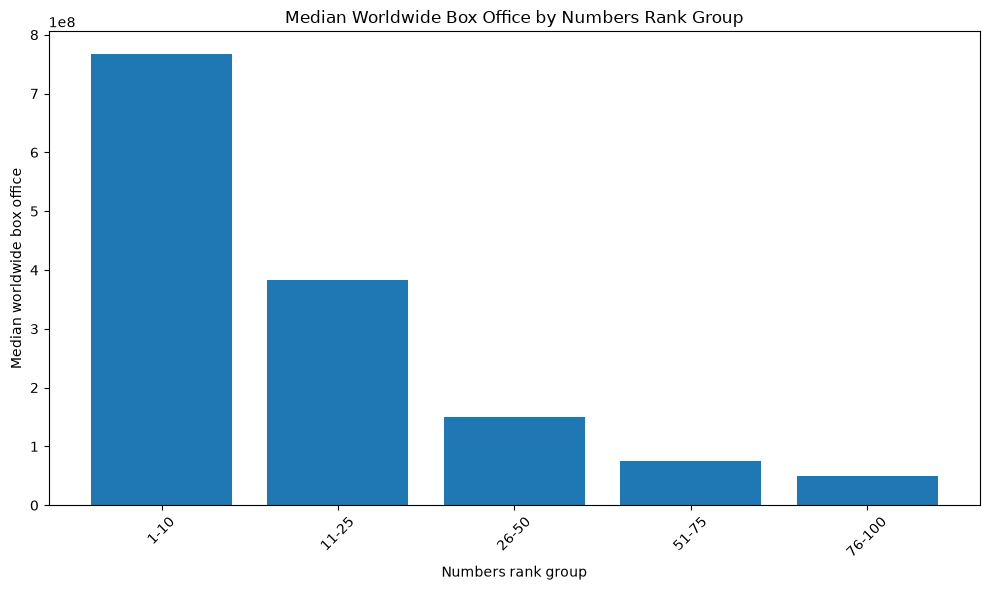

In [44]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(
    rank_analysis["rank_group"].astype(str),
    rank_analysis["median_worldwide"]
)

plt.xlabel("Numbers rank group")
plt.ylabel("Median worldwide box office")
plt.title("Median Worldwide Box Office by Numbers Rank Group")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

ça confirme le fait que rank est strongly associated with worldwide box office

In [1]:
rank_by_year = (
    df.groupby("year")
      .agg(
          n_movies=("rank", "count"),
          median_rank=("rank", "median"),
          mean_rank=("rank", "mean"),
          best_rank=("rank", "min"),
          worst_rank=("rank", "max")
      )
      .sort_index()
)


NameError: name 'df' is not defined

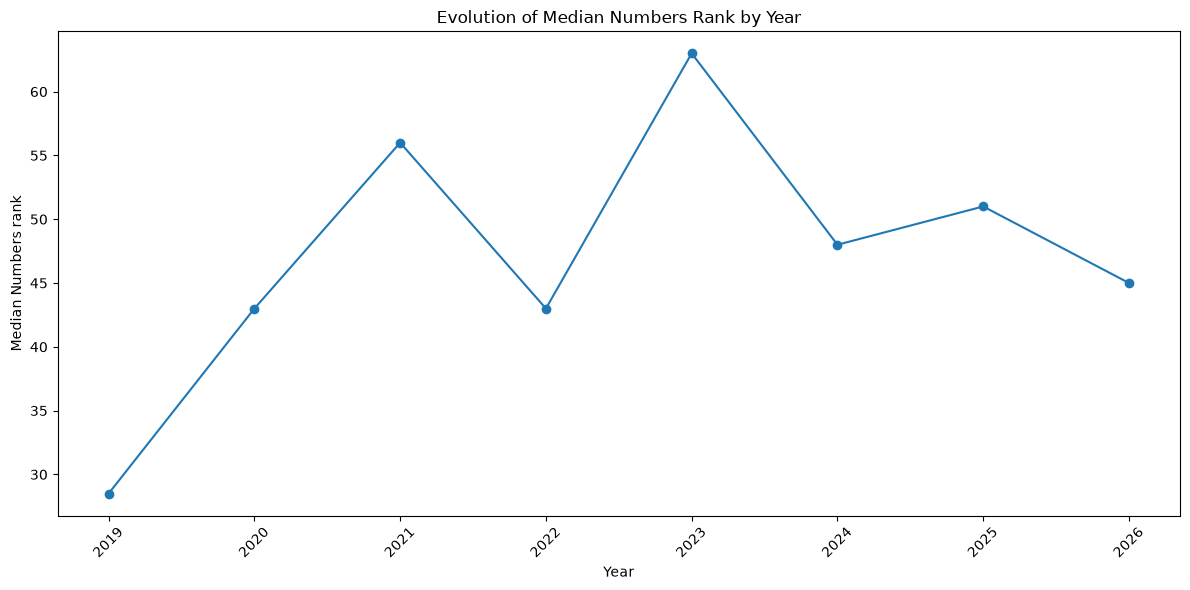

In [48]:
plt.figure(figsize=(12, 6))

plt.plot(
    rank_by_year.index,
    rank_by_year["median_rank"],
    marker="o"
)

plt.xlabel("Year")
plt.ylabel("Median Numbers rank")
plt.title("Evolution of Median Numbers Rank by Year")
plt.xticks(rank_by_year.index, rotation=45)

plt.tight_layout()
plt.show()

this shows our data (ranks of successfulyl merged movies) it has no additionnal value to the analysis (know if our merged data contains a lot of high ranked or or middle ranked or low ranked movies ) 

#### year vs rank_group 
show how much rank_groups generated money during the years

In [49]:
year_rank_analysis = (
    df.groupby(["year", "rank_group"], observed=True)
      .agg(
          n_movies=("worldwide_box_office", "count"),
          median_worldwide=("worldwide_box_office", "median"),
          mean_worldwide=("worldwide_box_office", "mean")
      )
      .reset_index()
)

year_rank_analysis

,year,rank_group,n_movies,median_worldwide,mean_worldwide
0,2019,1-10,10,1.104164e+09,1.315077e+09
1,2019,11-25,44,3.837101e+08,4.170634e+08
2,2019,26-50,22,2.466780e+08,2.421412e+08
3,2019,51-75,20,1.255157e+08,1.317713e+08
4,2019,76-100,18,7.426676e+07,7.656754e+07
5,2020,1-10,7,3.662736e+08,3.584223e+08
6,2020,11-25,8,1.361652e+08,1.513006e+08
7,2020,26-50,16,4.717716e+07,4.621895e+07
8,2020,51-75,11,2.191438e+07,2.274612e+07
9,2020,76-100,9,1.262417e+07,1.348883e+07


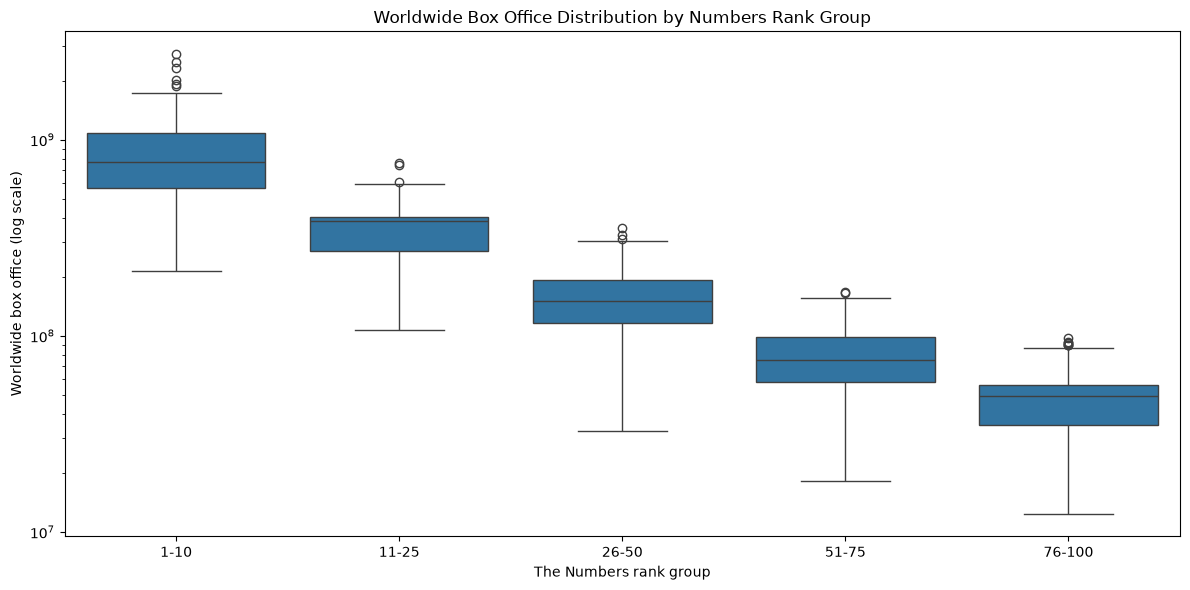

In [ ]:
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="rank_group",
    y="worldwide_box_office"
)

plt.yscale("log")
plt.xlabel("The Numbers rank group")
plt.ylabel("Worldwide box office (log scale)")
plt.title("Worldwide Box Office Distribution by Numbers Rank Group")

plt.tight_layout()
plt.show()

shows how many blockbusters(outliers) in each ranked_group --> best of each rank_group

those outliers whithin each rank_group have the highest ranks because rank is positivly correlated with worlwide box office

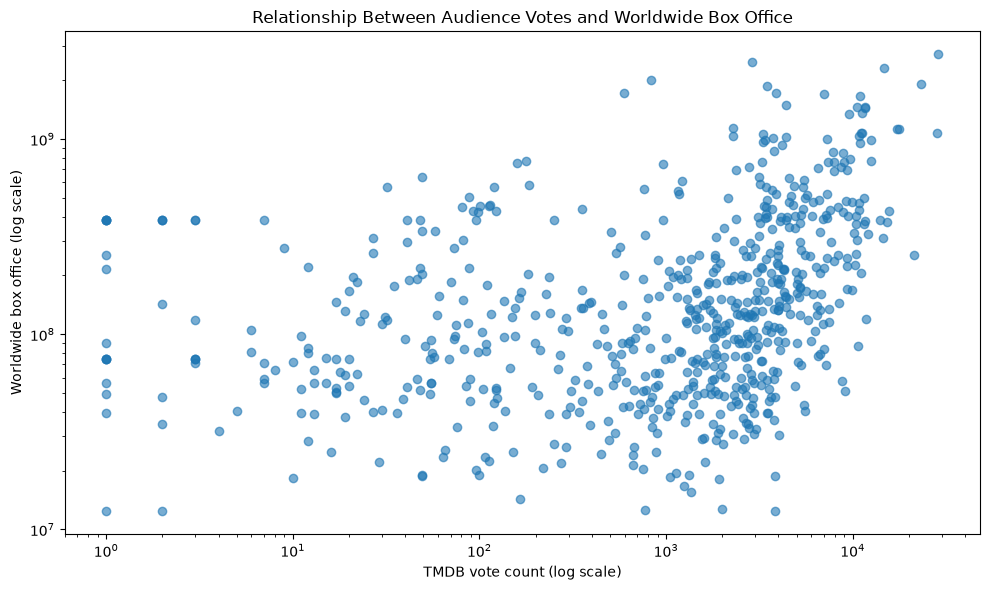

In [56]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["vote_count"],
    df["worldwide_box_office"],
    alpha=0.6
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("TMDB vote count (log scale)")
plt.ylabel("Worldwide box office (log scale)")
plt.title("Relationship Between Audience Votes and Worldwide Box Office")

plt.tight_layout()
plt.show()

no remark --> waiting for other results to comment on this log scaled scatter plot

1. Worldwide box office is strongly correlated with international and domestic box office, which is expected because both contribute to worldwide revenue.

2. A moderate positive relationship exists between TMDB vote count and worldwide box office, suggesting that movies receiving more user votes tend to be associated with higher commercial performance in this dataset.

3. Worldwide box office generally decreases as the numerical Numbers rank increases. This is consistent with the definition of the ranking and therefore should not be interpreted as a causal relationship.

4. The distribution of box office varies considerably between rank groups, with the highest-ranked movies generally showing higher median values and potentially greater dispersion.

5. The yearly analysis allows you to identify changes in the typical commercial performance of the selected top-100 movies between 2019 and 2025.